# Clases latentes de participacion

Analisis de clases latentes (LCA), la metodologia clasica en ciencia politica para tipologias de
votantes (habitual, intermitente, solo presidenciales, abstencionista). Cada eleccion se convierte
en un indicador categorico (participacion baja, media o alta frente al resto del pais) y el modelo
estima clases con un patron tipico de respuesta.

Ventajas frente a KMeans:
- Pertenencia probabilistica: cada celda tiene una probabilidad por clase, lo que permite
  identificar celdas ambiguas (buen blanco de campana).
- Seleccion de k con criterios de informacion (BIC, AIC) y entropia de clasificacion.

Limitacion: la unidad es la celda (seccion x sexo x grupo de edad), no la persona. Las clases
describen grupos de ciudadanos, no individuos.

Tiempo estimado: ~2 min (el EM corre sobre patrones unicos, no sobre celdas).

## 1. Configuracion

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

`INCLUIR_PJ` agrega la eleccion judicial 2025 como septimo indicador. `K_ELEGIDO = None` elige
el numero de clases automaticamente (ver seccion 5).

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

INCLUIR_PJ = False
N_CATEGORIAS = 3
ETIQUETAS_CAT = ["baja", "media", "alta"]

K_RANGO = range(2, 9)
K_VALIDO = range(4, 7)  # convocatoria pide 4-6 perfiles
K_ELEGIDO = None
MIN_PCT_CLASE = 5.0
UMBRAL_CLARA = 0.8

N_INIT = 20
MAX_ITER = 1000
TOL = 1e-8
N_BOOT = 5
N_EVAL = 10_000
RANDOM_STATE = 42

COLORES_PERFIL = ["#3288bd", "#66c2a5", "#fee08b", "#fdae61", "#f46d43", "#d53e4f",
                  "#9e0142", "#5e4fa2"]

## 3. Carga de datos

Mismo procedimiento que los notebooks 05-07: celdas del notebook 03, peso = SV + NV de 2024 y
solo casos completos.

In [3]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso", "P_PJ2025"])
    .reset_index(drop=True)
)
del pesos, secciones

celdas["MUJER"] = (celdas["SEXO"] == 1).astype(float)
celdas["RURAL_MIXTA"] = (celdas["TIPOSEC"].astype(str) != "U").astype(float)
w = celdas["peso"].to_numpy(dtype=float)
idx_eval = np.random.default_rng(RANDOM_STATE).choice(len(celdas), size=N_EVAL, replace=False, p=w / w.sum())
print(f"Celdas: {len(celdas):,}  peso: {w.sum():,.0f}")

Celdas: 644,887  peso: 68,606,422


## 4. Indicadores categoricos

### 4.1 Terciles ponderados por eleccion

Cada eleccion se corta en terciles ponderados por personas: baja, media y alta. Al ser relativos a
cada eleccion, eliminan el efecto comun de presidenciales contra intermedias. Lo que queda es la
posicion de cada celda frente al resto del pais en cada eleccion: una celda que es "alta" solo en
presidenciales aparece como un patron distinto de una que es "alta" siempre.

In [4]:
def terciles_ponderados(x, w, n=N_CATEGORIAS):
    orden = np.argsort(x)
    acum = np.cumsum(w[orden]) / w.sum()
    cortes = np.interp(np.arange(1, n) / n, acum, x[orden])
    return np.searchsorted(cortes, x, side="right")


INDICADORES = ELECCIONES + (["P_PJ2025"] if INCLUIR_PJ else [])
cat = np.column_stack([terciles_ponderados(celdas[c].to_numpy(dtype=float), w) for c in INDICADORES])

pd.DataFrame(
    {c: np.bincount(cat[:, j], weights=w, minlength=N_CATEGORIAS) / w.sum() * 100
     for j, c in enumerate(INDICADORES)},
    index=ETIQUETAS_CAT,
).round(1)

,P2009,P2012,P2015,P2018,P2021,P2024
baja,33.3,33.3,33.3,33.3,33.3,33.3
media,33.3,33.3,33.3,33.3,33.3,33.3
alta,33.3,33.4,33.3,33.3,33.4,33.3


### 4.2 Patrones de respuesta

El modelo solo depende del patron (la combinacion de categorias en las elecciones), asi que las
celdas se colapsan a patrones con su peso total. El peso se normaliza para sumar el numero de
celdas: las proporciones representan personas y el BIC usa n = celdas.

In [5]:
patrones, inv = np.unique(cat, axis=0, return_inverse=True)
inv = inv.ravel()
n_celdas = len(celdas)
J, C = len(INDICADORES), N_CATEGORIAS

w_pat = np.bincount(inv, weights=w)
f_pat = w_pat / w_pat.sum() * n_celdas

onehot = np.zeros((len(patrones), J * C))
onehot[np.arange(len(patrones))[:, None], np.arange(J) * C + patrones] = 1

print(f"Patrones observados: {len(patrones):,} de {C ** J:,} posibles")
top = pd.DataFrame(patrones, columns=INDICADORES).replace(dict(enumerate(ETIQUETAS_CAT)))
top["pct_personas"] = w_pat / w_pat.sum() * 100
top.sort_values("pct_personas", ascending=False).head(10).round(2)

Patrones observados: 728 de 729 posibles


,P2009,P2012,P2015,P2018,P2021,P2024,pct_personas
0,baja,baja,baja,baja,baja,baja,12.29
727,alta,alta,alta,alta,alta,alta,11.28
243,media,baja,baja,baja,baja,baja,2.29
485,media,alta,alta,alta,alta,alta,2.03
364,media,media,media,media,media,media,1.99
700,alta,alta,media,alta,alta,alta,1.57
270,media,baja,media,baja,baja,baja,1.57
27,baja,baja,media,baja,baja,baja,1.46
458,media,alta,media,alta,alta,alta,1.36
726,alta,alta,alta,alta,alta,media,1.17


## 5. Modelo

### 5.1 EM para clases latentes

Cada clase k tiene una proporcion `pi_k` y, para cada indicador j, una distribucion
`theta_kj` sobre las categorias. Los indicadores son independientes dentro de cada clase
(supuesto de independencia local). El EM alterna:

- **E:** probabilidad de cada clase dado el patron.
- **M:** `pi` y `theta` como promedios ponderados por esas probabilidades y por el peso del patron.

Se corren 20 inicializaciones aleatorias y se conserva la de mayor verosimilitud.

In [6]:
def ajustar_lca(K, f, seed):
    rng = np.random.default_rng(seed)
    pi = np.full(K, 1 / K)
    theta = rng.dirichlet(np.ones(C), size=(K, J))
    ll_prev = -np.inf
    for _ in range(MAX_ITER):
        log_p = np.log(pi) + onehot @ np.log(theta).reshape(K, J * C).T
        ll_fila = logsumexp(log_p, axis=1)
        resp = np.exp(log_p - ll_fila[:, None])
        ll = (f * ll_fila).sum()
        if ll - ll_prev < TOL * abs(ll):
            break
        ll_prev = ll
        rw = resp * f[:, None]
        pi = rw.sum(axis=0) / rw.sum()
        theta = (rw.T @ onehot).reshape(K, J, C) + 1e-10
        theta /= theta.sum(axis=2, keepdims=True)
    return {"pi": pi, "theta": theta, "ll": ll, "resp": resp}


def mejor_lca(K, f, seed=RANDOM_STATE, n_init=N_INIT):
    return max((ajustar_lca(K, f, seed + s) for s in range(n_init)), key=lambda m: m["ll"])


def entropia_relativa(resp, f):
    h = -(f[:, None] * resp * np.log(np.clip(resp, 1e-300, None))).sum()
    return 1 - h / (f.sum() * np.log(resp.shape[1]))

### 5.2 Numero de clases

- **BIC y AIC:** menor es mejor. Con 645k celdas el BIC suele seguir bajando al agregar clases, por
  eso se reporta tambien la mejora porcentual respecto a k - 1.
- **Entropia relativa:** de 0 a 1; cercana a 1 indica clases bien separadas.
- **pct_min:** tamano de la clase mas chica (% de personas).

In [7]:
modelos, filas = {}, []
for K in K_RANGO:
    m = mejor_lca(K, f_pat)
    modelos[K] = m
    n_par = (K - 1) + K * J * (C - 1)
    filas.append({
        "K": K, "loglik": m["ll"], "n_parametros": n_par,
        "BIC": -2 * m["ll"] + n_par * np.log(n_celdas),
        "AIC": -2 * m["ll"] + 2 * n_par,
        "entropia": entropia_relativa(m["resp"], f_pat),
        "pct_min": m["pi"].min() * 100,
    })

df_k = pd.DataFrame(filas)
df_k["mejora_BIC_pct"] = -df_k["BIC"].diff() / df_k["BIC"].shift().abs() * 100
df_k.round(3)

,K,loglik,n_parametros,BIC,AIC,entropia,pct_min,mejora_BIC_pct
0,2,-3416608.894,25,6833552.209,6833267.788,0.890,48.642,NaN
1,3,-3229706.087,38,6459920.494,6459488.175,0.846,30.040,5.468
2,4,-3194050.013,51,6388782.244,6388202.026,0.819,18.554,1.101
3,5,-3165785.213,64,6332426.542,6331698.425,0.778,13.642,0.882
4,6,-3141790.232,77,6284610.481,6283734.465,0.774,8.662,0.755
5,7,-3133063.521,90,6267330.956,6266307.042,0.750,9.465,0.275
6,8,-3126873.065,103,6255123.944,6253952.130,0.739,6.132,0.195


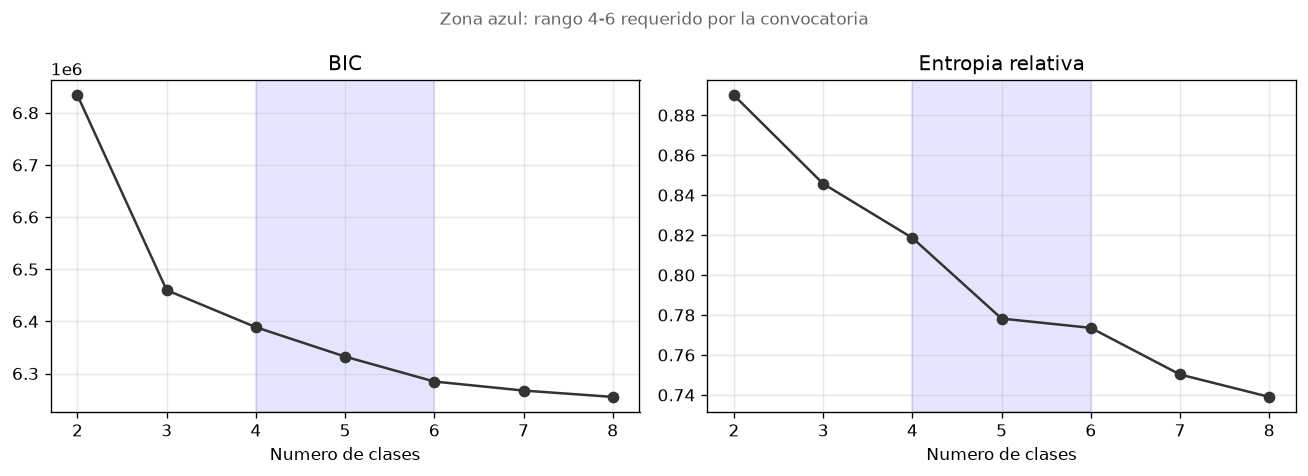

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(df_k["K"], df_k["BIC"], "o-", color="#333")
ax1.set_title("BIC")
ax2.plot(df_k["K"], df_k["entropia"], "o-", color="#333")
ax2.set_title("Entropia relativa")
for ax in (ax1, ax2):
    ax.axvspan(K_VALIDO.start, K_VALIDO.stop - 1, alpha=0.1, color="blue")
    ax.set_xlabel("Numero de clases")
    ax.grid(alpha=0.3)
plt.suptitle("Zona azul: rango 4-6 requerido por la convocatoria", fontsize=10, color="#666")
plt.tight_layout()
plt.show()

### 5.3 Eleccion de k

Si `K_ELEGIDO` es `None`: menor BIC dentro de 4-6 entre los modelos cuya clase mas chica tiene al
menos 5% de las personas.

In [9]:
if K_ELEGIDO is None:
    cand = df_k[df_k["K"].isin(K_VALIDO) & (df_k["pct_min"] >= MIN_PCT_CLASE)]
    cand = cand if len(cand) else df_k[df_k["K"].isin(K_VALIDO)]
    K_ELEGIDO = int(cand.loc[cand["BIC"].idxmin(), "K"])
print(f"K elegido: {K_ELEGIDO}")

K elegido: 6


## 6. Clases

### 6.1 Perfil de respuesta

Las clases se ordenan por su categoria esperada promedio (0 = la de menor participacion relativa).
Cada celda del mapa de calor es la probabilidad de que una celda de esa clase este en el tercil
alto (izquierda) o bajo (derecha) en cada eleccion.

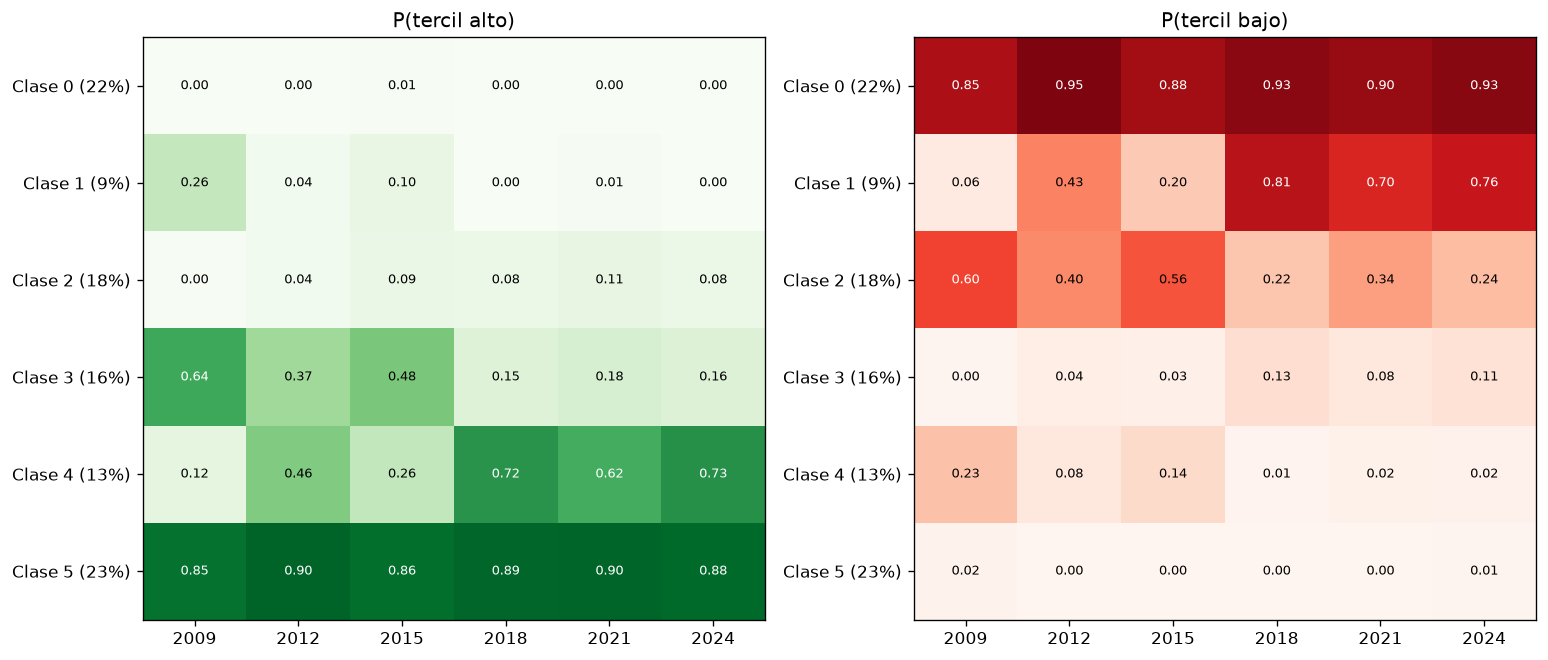

In [10]:
m = modelos[K_ELEGIDO]
orden = np.argsort((m["theta"] * np.arange(C)).sum(axis=2).mean(axis=1))
pi, theta, resp = m["pi"][orden], m["theta"][orden], m["resp"][:, orden]
nombres_clase = [f"Clase {k} ({pi[k] * 100:.0f}%)" for k in range(K_ELEGIDO)]

fig, axes = plt.subplots(1, 2, figsize=(13, 0.6 * K_ELEGIDO + 2))
for ax, c, titulo, cmap in [(axes[0], C - 1, "P(tercil alto)", "Greens"),
                            (axes[1], 0, "P(tercil bajo)", "Reds")]:
    datos = theta[:, :, c]
    ax.imshow(datos, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(J), [c[1:] if c in ELECCIONES else "PJ2025" for c in INDICADORES])
    ax.set_yticks(range(K_ELEGIDO), nombres_clase)
    for k in range(K_ELEGIDO):
        for j in range(J):
            ax.text(j, k, f"{datos[k, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if datos[k, j] > 0.6 else "black")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### 6.2 Asignacion de celdas

Cada celda recibe la clase mas probable de su patron. `prob_clase` es esa probabilidad; si es menor
a 0.8, la celda es ambigua entre clases.

In [11]:
clase_pat = resp.argmax(axis=1)
celdas["clase"] = clase_pat[inv]
celdas["prob_clase"] = resp.max(axis=1)[inv]
celdas["asignacion_clara"] = (celdas["prob_clase"] >= UMBRAL_CLARA).astype(float)

clara = np.average(celdas["asignacion_clara"], weights=w) * 100
print(f"Personas con asignacion clara (prob >= {UMBRAL_CLARA}): {clara:.1f}%")

Personas con asignacion clara (prob >= 0.8): 68.7%


### 6.3 Caracterizacion

Resumen ponderado por clase con las tasas reales (no los terciles): nivel, brecha, tendencia,
PJ 2025, composicion y porcentaje de personas con asignacion clara.

In [12]:
def media_ponderada(df, col, por):
    wx = (df[col] * df["peso"]).groupby([df[c] for c in por]).sum()
    return wx / df.groupby(por)["peso"].sum()


def dominante(df, por, col):
    t = df.groupby(por + [col])["peso"].sum()
    return t.groupby(level=por).idxmax().map(lambda x: x[-1])


def resumen(df, por):
    personas = df.groupby(por)["peso"].sum()
    out = pd.DataFrame({"personas": personas, "pct_pob": personas / df["peso"].sum() * 100})
    cols = ["promedio", "brecha_pres", "tendencia", "P_PJ2025", "MUJER", "RURAL_MIXTA",
            "asignacion_clara"]
    for col in cols:
        out[col] = media_ponderada(df, col, por)
    out[["MUJER", "RURAL_MIXTA", "asignacion_clara"]] *= 100
    out["edad_dominante"] = dominante(df, por, "GRUPO_EDAD")
    out["region_dominante"] = dominante(df, por, "REGION")
    return out.round(1)


resumen(celdas, ["clase"])

,personas,pct_pob,promedio,brecha_pres,tendencia,P_PJ2025,MUJER,RURAL_MIXTA,asignacion_clara,edad_dominante,region_dominante
clase,,,,,,,,,,,
0,14710683,21.4,37.4,14.3,1.1,11.1,25.2,26.3,92.2,30-39,Centro
1,5972226,8.7,48.9,7.8,-1.4,10.0,43.6,34.5,42.0,30-39,Occidente
2,12506271,18.2,50.5,18.7,3.0,14.0,52.8,23.6,60.3,30-39,Centro
3,11240135,16.4,60.4,9.3,-0.1,12.0,56.8,32.1,56.6,40-49,Centro
4,8099695,11.8,62.1,19.5,4.5,15.2,68.3,27.2,50.3,40-49,Centro
5,16077412,23.4,72.9,10.7,1.8,15.0,69.0,37.4,81.6,50-59,Centro


### 6.4 Trayectorias

Participacion ponderada real por clase en cada eleccion.

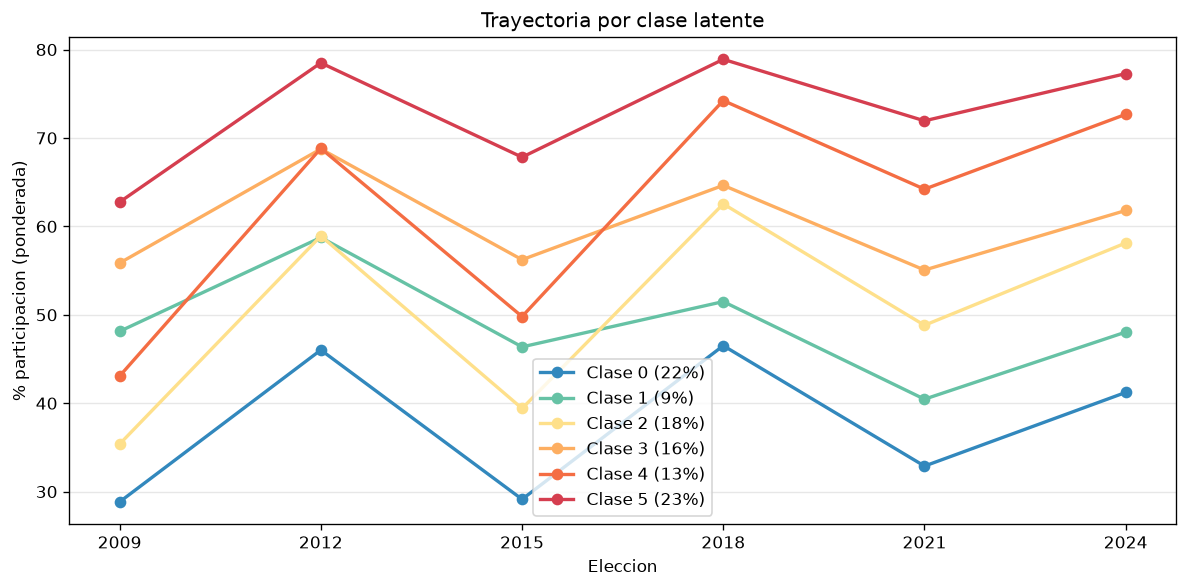

In [13]:
anos = [2009, 2012, 2015, 2018, 2021, 2024]
tray = pd.DataFrame({e: media_ponderada(celdas, e, ["clase"]) for e in ELECCIONES})

fig, ax = plt.subplots(figsize=(10, 5))
for k, fila in tray.iterrows():
    ax.plot(anos, fila.to_numpy(), "o-", color=COLORES_PERFIL[k], linewidth=2, label=nombres_clase[k])
ax.set_xticks(anos)
ax.set_xlabel("Eleccion")
ax.set_ylabel("% participacion (ponderada)")
ax.set_title("Trayectoria por clase latente")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Composicion por edad

Distribucion de edad dentro de cada clase (% de personas).

In [14]:
edad = celdas.groupby(["clase", "GRUPO_EDAD"])["peso"].sum().unstack(fill_value=0)[ETIQUETAS_EDAD]
(edad.div(edad.sum(axis=1), axis=0) * 100).round(1)

GRUPO_EDAD,18-24,25-29,30-39,40-49,50-59,60-69,70-79,80+
clase,,,,,,,,
0,28.9,27.2,31.0,8.2,2.1,0.5,0.4,1.7
1,20.1,13.7,27.3,21.7,10.5,3.5,2.2,1.0
2,22.0,14.4,30.8,18.5,7.8,2.8,2.2,1.6
3,10.0,5.5,18.0,26.1,23.9,11.3,4.7,0.3
4,9.0,4.3,18.0,25.5,21.7,13.4,7.7,0.4
5,3.4,2.0,9.1,19.6,28.8,27.6,9.4,0.1


## 7. Estabilidad y comparacion

### 7.1 Bootstrap

Bootstrap de Poisson sobre las celdas (peso x Poisson(1)), se reagregan los patrones y se reajusta
el modelo con el mismo k. ARI de la clase asignada contra la original en la muestra eval.

In [15]:
aris = []
for b in range(N_BOOT):
    w_b = w * np.random.default_rng(1000 + b).poisson(1.0, size=len(w))
    f_b = np.bincount(inv, weights=w_b, minlength=len(patrones))
    f_b = f_b / f_b.sum() * n_celdas
    m_b = mejor_lca(K_ELEGIDO, f_b, seed=1000 + b * N_INIT, n_init=10)
    clase_b = m_b["resp"].argmax(axis=1)[inv]
    aris.append(adjusted_rand_score(celdas["clase"].to_numpy()[idx_eval], clase_b[idx_eval]))
print(f"ARI medio: {np.mean(aris):.3f}  minimo: {np.min(aris):.3f}")

ARI medio: 0.990  minimo: 0.967


### 7.2 Comparacion con modelos previos

ARI contra los modelos guardados por los notebooks 05-07 (solo los archivos que existan).

In [16]:
llaves = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
comparar = {
    "celdas_perfiles_candidatos.parquet": ["base_04", "candidato_1"],
    "celdas_perfiles_candidatos_forma.parquet": ["forma_1"],
    "celdas_jerarquia.parquet": ["perfil"],
}
for archivo, cols in comparar.items():
    ruta = DIR_PREPROCESSED / archivo
    if not ruta.exists():
        print(f"No existe {archivo}")
        continue
    otro = celdas[llaves].merge(pd.read_parquet(ruta, columns=llaves + cols), on=llaves, how="left")
    for col in cols:
        etiquetas = otro[col].fillna(-1).astype(int).to_numpy()[idx_eval]
        ari = adjusted_rand_score(celdas["clase"].to_numpy()[idx_eval], etiquetas)
        print(f"ARI vs {archivo} [{col}]: {ari:.3f}")

ARI vs celdas_perfiles_candidatos.parquet [base_04]: 0.336
ARI vs celdas_perfiles_candidatos.parquet [candidato_1]: 0.384
ARI vs celdas_perfiles_candidatos_forma.parquet [forma_1]: 0.087


ARI vs celdas_jerarquia.parquet [perfil]: 0.268


## 8. Exportacion

In [17]:
clases = resumen(celdas, ["clase"])
for j, c in enumerate(INDICADORES):
    clases[f"p_alta_{c}"] = pd.Series(theta[:, j, C - 1], index=range(K_ELEGIDO)).round(3)

salidas = {
    "celdas_clases_latentes.parquet": celdas[llaves + ["peso", "clase", "prob_clase"]],
    "lca_seleccion_k.csv": df_k,
    "lca_clases.csv": clases,
}
for nombre, df in salidas.items():
    ruta = DIR_PREPROCESSED / nombre
    if nombre.endswith(".parquet"):
        df.to_parquet(ruta, index=False)
    else:
        df.to_csv(ruta, index=nombre == "lca_clases.csv")
    print(f"{nombre}: {ruta.stat().st_size / 1024:.0f} KB")

celdas_clases_latentes.parquet: 2256 KB
lca_seleccion_k.csv: 1 KB
lca_clases.csv: 1 KB
